In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [7]:
df = pd.read_csv("insurance.csv")
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [8]:
print("Shape:", df.shape)
df.info()
df.describe()
print("\nMissing values:\n", df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())

Shape: (1338, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB

Missing values:
 age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64
Duplicate rows: 1


In [10]:
target = "charges"
if target not in df.columns:
    raise ValueError(f"Expected target column '{target}'. Found: {list(df.columns)}")
df = df.drop_duplicates().copy()
df[target] = pd.to_numeric(df[target], errors="coerce")
df = df.dropna(subset=[target])
numeric_features = df.select_dtypes(include="number").columns.drop(target, errors="ignore").tolist()
categorical_features = df.select_dtypes(exclude="number").columns.tolist()
feature_columns = numeric_features + categorical_features
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['age', 'bmi', 'children']
Categorical features: ['sex', 'smoker', 'region']


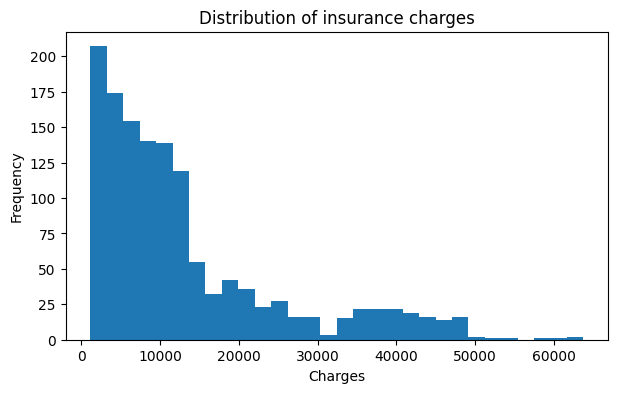

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(df[target], bins=30)
ax.set_title("Distribution of insurance charges")
ax.set_xlabel("Charges")
ax.set_ylabel("Frequency")
plt.show()

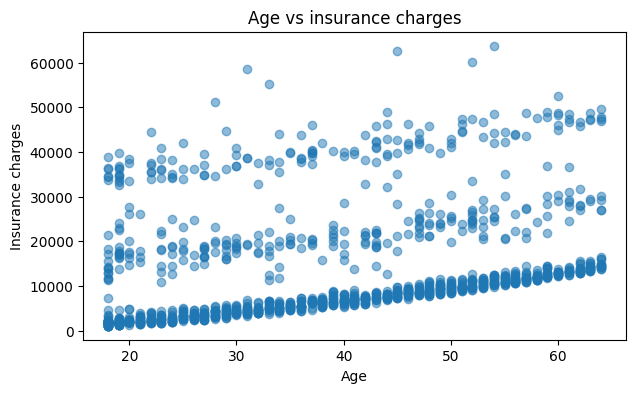

In [12]:
if "age" in df.columns:
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.scatter(df["age"], df[target], alpha=0.5)
    ax.set_xlabel("Age")
    ax.set_ylabel("Insurance charges")
    ax.set_title("Age vs insurance charges")
    plt.show()

In [14]:
X = df[feature_columns]
y = df[target]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()
preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

In [15]:
linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])
ridge_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge(alpha=10.0))
])

linear_model.fit(X_train, y_train)
ridge_model.fit(X_train, y_train)

linear_pred = linear_model.predict(X_test)
ridge_pred = ridge_model.predict(X_test)

In [16]:
def regression_metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": mean_squared_error(actual, predicted) ** 0.5,
        "R2": r2_score(actual, predicted)
    }

comparison = pd.DataFrame({
    "Linear Regression": regression_metrics(y_test, linear_pred),
    "Ridge Regression": regression_metrics(y_test, ridge_pred)
}).T
comparison

,MAE,RMSE,R2
Linear Regression,4177.045561,5956.342894,0.806929
Ridge Regression,4260.144629,6039.361926,0.801509


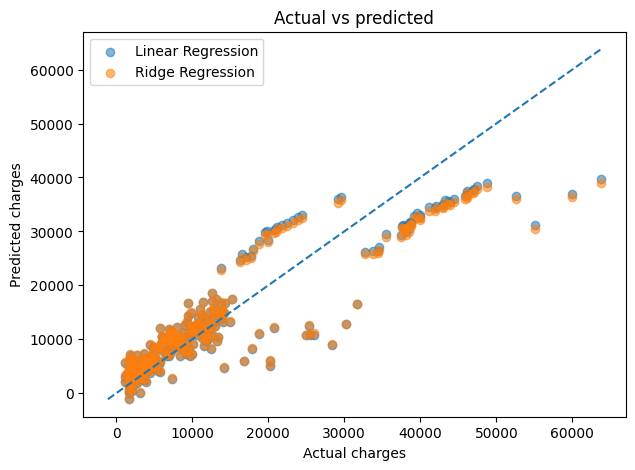

In [17]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(y_test, linear_pred, alpha=0.55, label="Linear Regression")
ax.scatter(y_test, ridge_pred, alpha=0.55, label="Ridge Regression")
low = min(y_test.min(), linear_pred.min(), ridge_pred.min())
high = max(y_test.max(), linear_pred.max(), ridge_pred.max())
ax.plot([low, high], [low, high], "--")
ax.set_xlabel("Actual charges")
ax.set_ylabel("Predicted charges")
ax.set_title("Actual vs predicted")
ax.legend()
plt.show()

In [18]:
alpha_values = [0.01, 0.1, 1, 10, 50, 100]
alpha_rows = []

for alpha in alpha_values:
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("model", Ridge(alpha=alpha))
    ])
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    alpha_rows.append({
        "alpha": alpha,
        "MAE": mean_absolute_error(y_test, prediction),
        "RMSE": mean_squared_error(y_test, prediction) ** 0.5,
        "R2": r2_score(y_test, prediction)
    })

alpha_results = pd.DataFrame(alpha_rows)
alpha_results

,alpha,MAE,RMSE,R2
0,0.01,4177.129432,5956.421784,0.806924
1,0.10,4177.884034,5957.132205,0.806878
2,1.00,4185.406967,5964.276526,0.806414
3,10.00,4260.144629,6039.361926,0.801509
4,50.00,4587.978323,6421.673045,0.775584
5,100.00,4953.573025,6925.021891,0.739024


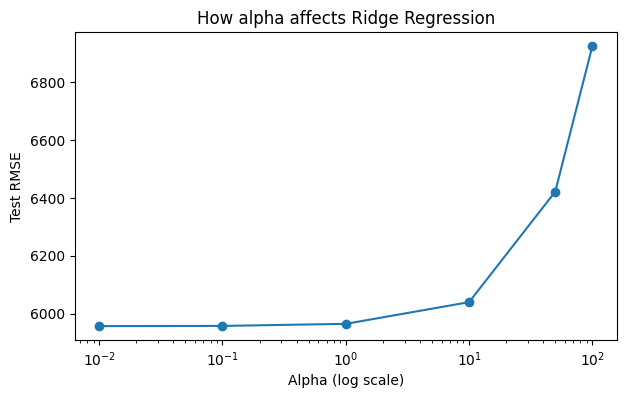

In [19]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(alpha_results["alpha"], alpha_results["RMSE"], marker="o")
ax.set_xscale("log")
ax.set_xlabel("Alpha (log scale)")
ax.set_ylabel("Test RMSE")
ax.set_title("How alpha affects Ridge Regression")
plt.show()